# 19 - The Laplace transform

**MATH 331 - Differential Equations.** Lecture plan, Unit 10: Session 23 (Sections 2-4) and Session 24
(Sections 5-6).

**References:** J. Lebl, *Notes on Diffy Qs*, Sections 6.1 and 6.2 and exercises of Chapter 6; W.A. Adkins
and M.G. Davidson, *Ordinary Differential Equations*, Section 3.7 (the circuit); notebooks 06, 07, 14, 15;
videos R03 (integration by parts), R04 (partial fractions).

**What you will learn**
1. The Laplace transform of $f(t)$ is an integral, so for each $s$ it is a number: you can compute it,
   draw it, and compare it with a table.
2. To come back from $F(s)$ to $f(t)$: partial fractions, then the table read from right to left.
3. The transform turns a derivative into a multiplication by $s$, so an initial value problem becomes an
   equation of algebra, with the initial values already inside it.

## 1. Before you start

**What you need.**
* *Integration by parts* (video R03): $\int u\,v'\,dt = u\,v - \int u'\,v\,dt$.
* *Partial fractions* (video R04): a quotient of polynomials written as a sum of simple fractions.
* *The three cases of notebook 06:* the roots of $ar^2 + br + c = 0$ are real and different, real and
  equal, or a complex pair $\alpha \pm i\beta$, which gives $e^{\alpha t}\cos\beta t$ and
  $e^{\alpha t}\sin\beta t$.

**Conventions (the whole notebook).**
* $t \ge 0$ is the time, and $t = 0$ is when the problem starts. $s$ is the variable of the transform, a
  real number here. The exponent of $e^{-st}$ must be a pure number: if $t$ is in seconds, $s$ is in
  1/second (the unit is written out, because the letter $s$ is taken).
* Functions of time are in lower case, $f(t)$, $g(t)$, $x(t)$, and their transforms in upper case,
  $F(s)$, $G(s)$, $X(s)$ (Lebl).
* The transform is written $\mathcal{L}\{f(t)\}$, with a script L and braces. It is not the operator
  $L[y]$ of Session 11, and not the inductance $L$ of a circuit (Section 6).
* The table is Lebl's: $e^{-at}$ goes with $1/(s + a)$. Many books print $e^{at}$ with $1/(s - a)$: the
  same row with $-a$ in place of $a$.
* The examples of Lebl that are used here have no units; the circuit of Section 6 states its own.
* Lebl's exercise numbers are those of the list at the end of his Chapter 6, except where "in the text"
  is written.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: laplace_numeric, laplace_table, forced_response, free_response, characteristic_roots,
# damping_regime, check, check_formula).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


In [2]:
# SymPy's letters t and s, for formulas; a number chosen for s has its own name (S_ONE, S_DEMO, ...)
t, s = sp.symbols("t s", positive=True)

## 2. The transform is an integral

(Session 23.) *In class:* this section with its two cells, its figure and its slider; in Section 3 the
table and its check; in Section 4 Lebl's Examples 6.1.6 and 6.1.7 with their figure. *At home:* linearity
and the range of $s$ (the second half of Section 3), the procedure at the end of Section 4.

*Lebl, Section 6.1.1:*

$$ F(s) = \mathcal{L}\{f(t)\} = \int_0^\infty e^{-st} f(t)\,dt . $$

Lebl calls it "a black box that eats functions and spits out functions in a new variable". Inside the
box: choose a number $s$; multiply $f(t)$ by the **weight** $e^{-st}$, which is 1 at $t = 0$ and, for
$s > 0$, dies out as $t$ grows; the area under the product is the number $F(s)$. Another $s$, another
area: $F$ is a function of $s$.

**An integral up to infinity is a limit:** $\int_0^\infty = \lim_{T \to \infty}\int_0^T$.
*Lebl, Example 6.1.1,* $f(t) = 1$. Inside the integral $s$ is a fixed number and the variable is $t$. The
derivative of $e^{-st}$ with respect to $t$ is $-s\,e^{-st}$, so an antiderivative of $e^{-st}$ is
$-e^{-st}/s$:

$$ \int_0^T e^{-st}\,dt = \Big[-\frac{e^{-st}}{s}\Big]_0^T = -\frac{e^{-sT}}{s} + \frac{1}{s}
   = \frac{1 - e^{-sT}}{s} \;\longrightarrow\; \frac1s \quad (T \to \infty), $$

because $e^{-sT} \to 0$ when $s > 0$. For $s \le 0$ there is no limit (for $s < 0$, $e^{-sT}$ grows
without bound; for $s = 0$ the integral is $T$ itself): $\mathcal{L}\{1\} = 1/s$ **only for $s > 0$**.
The code computes the integral up to $T = 1, 5, 20$ for $s = 1$.

In [3]:
S_ONE = 1.0                                 # the value of s (try 0.1 or -1; not 0: a division by zero)
UPPER_LIMITS = (1.0, 5.0, 20.0)             # T: the integral is taken from 0 to T
SUM_POINTS = 20001                          # points of the sum that approximates the integral
SUM_AGREEMENT = 1e-6                        # the sum against the formula (relative)

print(f"the integral of e^(-st) from 0 to T, for s = {S_ONE:g} (1/s = {1 / S_ONE:g})")
print("     T   by a sum   (1 - e^(-sT))/s")
for upper in UPPER_LIMITS:
    times = np.linspace(0.0, upper, SUM_POINTS)
    by_sum = np.trapezoid(np.exp(-S_ONE * times), times)       # the area of many thin trapezoids
    by_formula = (1 - np.exp(-S_ONE * upper)) / S_ONE
    print(f"{upper:6g} {by_sum:10.6f} {by_formula:13.6f}")
    assert np.isclose(by_sum, by_formula, rtol=SUM_AGREEMENT)

the integral of e^(-st) from 0 to T, for s = 1 (1/s = 1)
     T   by a sum   (1 - e^(-sT))/s
     1   0.632121      0.632121
     5   0.993262      0.993262
    20   1.000000      1.000000


*Lebl, Example 6.1.2:* $\mathcal{L}\{e^{-at}\} = \int_0^\infty e^{-(s + a)t}\,dt = \dfrac{1}{s + a}$ for
$s > -a$ (the integral above with $s + a$ in place of $s$; $s > -a$ is $s + a > 0$, the condition
$s > 0$ of Example 6.1.1 for the number $s + a$).

*Lebl, Example 6.1.3,* $f(t) = t$, by parts with $u = t$ and $v' = e^{-st}$, so $u' = 1$ and
$v = -e^{-st}/s$:

$$ \mathcal{L}\{t\} = \Big[t\cdot\Big(-\frac{e^{-st}}{s}\Big)\Big]_0^\infty
   - \int_0^\infty 1\cdot\Big(-\frac{e^{-st}}{s}\Big)dt
   = \Big[-\frac{t\,e^{-st}}{s}\Big]_0^\infty + \frac1s\int_0^\infty e^{-st}\,dt
   = 0 + \frac1s\cdot\frac1s = \frac{1}{s^2}, \qquad s > 0 . $$

A bracket with $\infty$ on top means: the limit of its value at $T$ as $T \to \infty$, minus its value at
0. Here both are 0: at $t = 0$ because of the factor $t$; at infinity because $e^{-st}$ dies out faster
than $t$ grows (for $s = 1$: $te^{-t}$ is 0.0005 at $t = 10$ and 0.00000004 at $t = 20$).

`ol.laplace_numeric(f, s)` computes the integral numerically, with no table inside it. In
`lambda t: ...` the letter `t` is a number, the time at which the function is evaluated.

In [4]:
S_DEMO = 3.0                                # the value of s
DECAY = 2.0                                 # the a of e^(-at)
EXAMPLES = (("1", lambda t: 1.0, 1 / S_DEMO),                             # Lebl, Example 6.1.1: 1/s
            ("t", lambda t: t, 1 / S_DEMO ** 2),                          # Example 6.1.3: 1/s^2
            (f"e^(-{DECAY:g}t)", lambda t: np.exp(-DECAY * t), 1 / (S_DEMO + DECAY)))    # 6.1.2: 1/(s + a)
for name, f, by_formula in EXAMPLES:
    by_integral = ol.laplace_numeric(f, S_DEMO)
    # (in an f-string the doubled braces {{ and }} print one brace each)
    print(f"L{{{name}}} at s = {S_DEMO:g}: the integral gives {by_integral:.8f}, "
          f"the formula {by_formula:.8f}")
    assert np.isclose(by_integral, by_formula)              # np.isclose: equal to 5 significant digits
# try: another S_DEMO (larger than 0), another DECAY (0 or more)

L{1} at s = 3: the integral gives 0.33333333, the formula 0.33333333
L{t} at s = 3: the integral gives 0.11111111, the formula 0.11111111
L{e^(-2t)} at s = 3: the integral gives 0.20000000, the formula 0.20000000


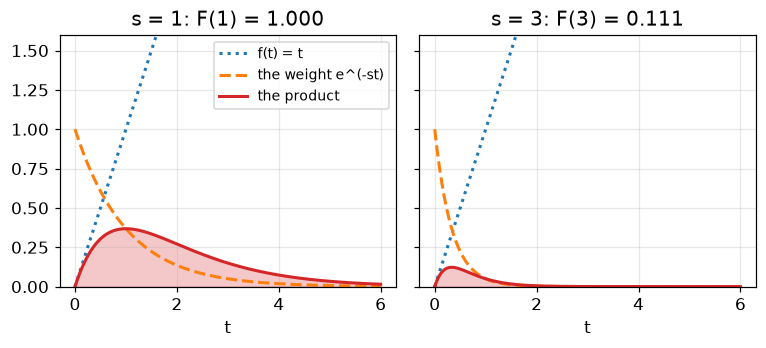

In [5]:
# drawing code: you can skip reading it
WIDE_FIGURE = (7.0, 3.3)                    # two panels side by side
CURVE_POINTS = 400
T_SHOWN = 6.0                               # the part of the t axis that is drawn
HEIGHT_SHOWN = 1.6
S_PAIR = (1.0, 3.0)                         # the two values of s of the figure
SHADE = 0.25                                # how dark the shaded area is


def ramp(t):
    return t                                # f(t) = t


def draw_product(ax, f, name, s_value, t_end):
    # f, the weight e^(-st) and their product on [0, t_end]; the area under the product is shaded
    times = np.linspace(0.0, t_end, CURVE_POINTS)
    weight = np.exp(-s_value * times)
    ax.plot(times, f(times), ":", color="C0", linewidth=2, label=name)
    ax.plot(times, weight, "--", color="C1", linewidth=2, label="the weight e^(-st)")
    ax.plot(times, weight * f(times), "-", color="C3", linewidth=2, label="the product")
    ax.fill_between(times, 0.0, weight * f(times), color="C3", alpha=SHADE)
    ax.set_xlabel("t")


fig, panels = plt.subplots(1, 2, figsize=WIDE_FIGURE, sharey=True)
for ax, s_value in zip(panels, S_PAIR):
    draw_product(ax, ramp, "f(t) = t", s_value, T_SHOWN)
    area = ol.laplace_numeric(ramp, s_value)
    ax.set_title(f"s = {s_value:g}: F({s_value:g}) = {area:.3f}")
    ax.set_ylim(0.0, HEIGHT_SHOWN)
    assert np.isclose(area, 1 / s_value ** 2)
panels[0].legend(loc="upper right")
plt.tight_layout()
plt.show()

*The plot shows* $f(t) = t$ (dotted), the weight $e^{-st}$ (dashed) and their product (solid) for $s = 1$
and $s = 3$. The shaded area, continued to the right for ever, is $F(s)$: 1 for $s = 1$ and
$1/9 = 0.111$ for $s = 3$.

**Slider: one area for each $s$.** $f(t) = t$ again, and $s$ from 0.5 to 5. Before moving it:
$F(1) = 1$. If $s$ is doubled, from 1 to 2, is the area halved, or less than half?

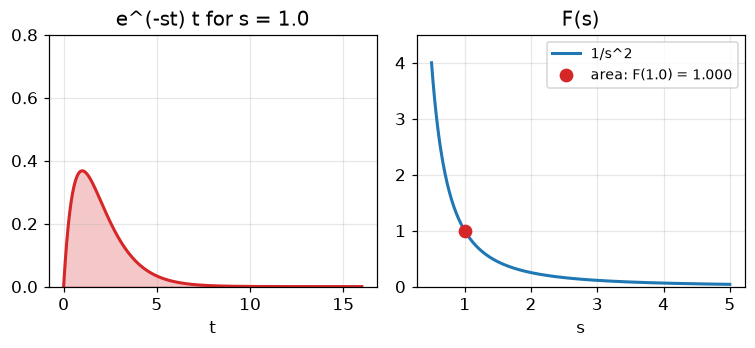

In [6]:
DEFAULT_S = 1.0
S_RANGE = (0.5, 5.0, 0.1)                   # minimum, maximum, step
T_SLIDER = 16.0                             # the t axis of the left panel
PRODUCT_HEIGHT = 0.8                        # the vertical axis of the left panel
TRANSFORM_HEIGHT = 4.5                      # the vertical axis of the right panel
POINT_SIZE = 8                              # markers: a point
S_CURVE = np.linspace(S_RANGE[0], S_RANGE[1], CURVE_POINTS)


def plot_area(s=DEFAULT_S):
    # (inside this function s is the number chosen with the slider)
    # left: the product e^(-st) t and its area; right: that area as the point (s, F(s)) on the curve 1/s^2
    area = ol.laplace_numeric(ramp, s)
    times = np.linspace(0.0, T_SLIDER, CURVE_POINTS)
    product = np.exp(-s * times) * ramp(times)
    fig, (left, right) = plt.subplots(1, 2, figsize=WIDE_FIGURE)
    left.plot(times, product, "-", color="C3", linewidth=2)
    left.fill_between(times, 0.0, product, color="C3", alpha=SHADE)
    left.set_ylim(0.0, PRODUCT_HEIGHT)
    left.set_xlabel("t")
    left.set_title(f"e^(-st) t for s = {s:.1f}")
    right.plot(S_CURVE, 1 / S_CURVE ** 2, "-", color="C0", linewidth=2, label="1/s^2")
    right.plot(s, area, "o", color="C3", markersize=POINT_SIZE, label=f"area: F({s:.1f}) = {area:.3f}")
    right.set_ylim(0.0, TRANSFORM_HEIGHT)
    right.set_xlabel("s")
    right.set_title("F(s)")
    right.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


plot_area()

In [7]:
interact(plot_area, s=FloatSlider(value=DEFAULT_S, min=S_RANGE[0], max=S_RANGE[1], step=S_RANGE[2],
                                  description="s", continuous_update=False));

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='s', max=5.0, min=0.5), Outp...

*The static plot shows*, for $s = 1$, the product $te^{-t}$ and its area (left), and that area as the
point $(1, 1)$ on the curve $1/s^2$ (right).

(Answer: less than half: $F(2) = 0.25$, a quarter, because $F(s) = 1/s^2$. A larger $s$ makes the weight
$e^{-st}$ smaller at every $t > 0$, so the hump is lower and ends sooner, and its area is smaller (here
$f(t) = t$ is positive): from 4 at $s = 0.5$ to 0.04 at $s = 5$.)

## 3. The table

(Session 23.) Nobody computes these integrals twice: the results are kept in a table. Lebl's Table 6.1.1
($C$, $a$ and $\omega > 0$ are constants, $n = 0, 1, 2, \dots$; its last row, for the step function
$u(t - a)$, waits for notebook 20):

| $f(t)$ | $F(s) = \mathcal{L}\{f(t)\}$ | holds for |
|---|---|---|
| $C$ | $\dfrac{C}{s}$ | $s > 0$ |
| $t$ | $\dfrac{1}{s^2}$ | $s > 0$ |
| $t^2$ | $\dfrac{2}{s^3}$ | $s > 0$ |
| $t^3$ | $\dfrac{6}{s^4}$ | $s > 0$ |
| $t^n$ | $\dfrac{n!}{s^{n+1}}$ | $s > 0$ |
| $e^{-at}$ | $\dfrac{1}{s + a}$ | $s > -a$ |
| $\sin\omega t$ | $\dfrac{\omega}{s^2 + \omega^2}$ | $s > 0$ |
| $\cos\omega t$ | $\dfrac{s}{s^2 + \omega^2}$ | $s > 0$ |
| $\sinh\omega t$ | $\dfrac{\omega}{s^2 - \omega^2}$ | $s > \omega$ |
| $\cosh\omega t$ | $\dfrac{s}{s^2 - \omega^2}$ | $s > \omega$ |

($n! = 1 \cdot 2 \cdots n$, with $0! = 1$; $\sinh x = (e^x - e^{-x})/2$ and $\cosh x = (e^x + e^{-x})/2$:
Exercise 3(ii).) `ol.laplace_table()` holds this table as nine rows, with $C = 1$, $a = 2$, $\omega = 3$
and $t^3$ as the row $t^n$ with $n = 3$. The code checks every row against the integral at three values
of $s$, and against SymPy's own `sp.laplace_transform`.

In [8]:
# checking code: you can skip reading it; read what it prints
S_CHECKS = (0.5, 1.0, 4.0)                  # a row is checked at s = (the edge of its range) + 0.5, + 1, + 4
TABLE_AGREEMENT = 1e-7                      # the integral against the formula (relative)
table = ol.laplace_table()                  # with a = 2, omega = 3, n = 3
rows = {row.name: row for row in table}     # a row by its name: rows["t^2"]
a_demo, omega_demo = sp.nsimplify(ol.LAPLACE_DEMO_A), sp.nsimplify(ol.LAPLACE_DEMO_OMEGA)
IN_SYMPY = {"1": sp.Integer(1), "t": t, "t^2": t ** 2, "t^n": t ** ol.LAPLACE_DEMO_N,
            "e^(-at)": sp.exp(-a_demo * t), "sin": sp.sin(omega_demo * t), "cos": sp.cos(omega_demo * t),
            "sinh": sp.sinh(omega_demo * t), "cosh": sp.cosh(omega_demo * t)}     # the same nine functions
assert tuple(IN_SYMPY) == ol.LAPLACE_ROW_NAMES

print(f"Lebl's Table 6.1.1 with a = {ol.LAPLACE_DEMO_A:g}, omega = {ol.LAPLACE_DEMO_OMEGA:g}, "
      f"n = {ol.LAPLACE_DEMO_N}")
print(f"{'f(t)':15s}{'F(s)':24s}{'holds for':11s}{'F(s) at the three s: table - integral'}")
for row in table:
    places = [row.s_min + offset for offset in S_CHECKS]
    by_table = np.array([row.transform(place) for place in places])
    by_integral = np.array([ol.laplace_numeric(row.time, place) for place in places])
    assert np.allclose(by_integral, by_table, rtol=TABLE_AGREEMENT, atol=0.0)
    by_sympy = sp.laplace_transform(IN_SYMPY[row.name], t, s, noconds=True)     # noconds: only F(s)
    assert np.isclose(float(by_sympy.subs(s, places[-1])), by_table[-1])
    print(f"{row.time_text:15s}{row.transform_text:24s}{'s > ' + format(row.s_min, 'g'):11s}"
          f"at most {np.max(np.abs(by_table - by_integral)):.0e}")
print(f"sp.laplace_transform agrees on all {len(table)} rows; for example L{{sin(3t)}} =",
      sp.laplace_transform(IN_SYMPY["sin"], t, s, noconds=True))

Lebl's Table 6.1.1 with a = 2, omega = 3, n = 3
f(t)           F(s)                    holds for  F(s) at the three s: table - integral
1              1/s                     s > 0      at most 0e+00


t              1/s^2                   s > 0      at most 0e+00
t^2            2/s^3                   s > 0      at most 2e-15
t^n            n!/s^(n + 1)            s > 0      at most 0e+00
e^(-a t)       1/(s + a)               s > -2     at most 0e+00


sin(omega t)   omega/(s^2 + omega^2)   s > 0      at most 1e-15
cos(omega t)   s/(s^2 + omega^2)       s > 0      at most 1e-15
sinh(omega t)  omega/(s^2 - omega^2)   s > 3      at most 6e-17


cosh(omega t)  s/(s^2 - omega^2)       s > 3      at most 2e-16
sp.laplace_transform agrees on all 9 rows; for example L{sin(3t)} = 3/(s**2 + 9)


*The table shows* that for every row the formula and the integral agree to at least 9 decimal places
(2e-16 means $2 \cdot 10^{-16}$).

**Linearity** (Lebl, Theorem 6.1.1). The integral of a sum is the sum of the integrals, and a constant
factor comes out: $\mathcal{L}\{Af(t) + Bg(t)\} = AF(s) + BG(s)$. So the table also transforms every sum
of multiples of its rows. *Lebl, Exercise 6.1.12:* $4(t + 1)^2 = 4t^2 + 8t + 4$, so

$$ \mathcal{L}\{4(t + 1)^2\} = 4\cdot\frac{2}{s^3} + 8\cdot\frac{1}{s^2} + 4\cdot\frac{1}{s}
   = \frac{8}{s^3} + \frac{8}{s^2} + \frac{4}{s} \quad\text{(the book's answer).} $$

**Not for products** (Lebl's warning): $\mathcal{L}\{f(t)g(t)\}$ is in general **not** $F(s)G(s)$. With
$f(t) = g(t) = t$ at $s = 2$: $\mathcal{L}\{t^2\} = 2/s^3 = 1/4$, but $(1/s^2)^2 = 1/16$.

**The range of $s$.** Each row holds only for $s$ large enough. $e^{2t}$ is the row $e^{-at}$ with
$a = -2$: its transform is $1/(s - 2)$ for $s > 2$; for $s \le 2$ the product $e^{-st}e^{2t}$ does not die
out, and the area is infinite.

A function is of **exponential order** when it grows no faster than some exponential:
$|f(t)| \le Me^{ct}$ for some constants $M$ and $c$. Then (and if $f$ is continuous) $F(s)$ exists for
all $s > c$ (Lebl, Theorem 6.1.2), and $F(s) \to 0$ as $s \to \infty$. Examples: $t^2$, $\sin t$,
$e^{2t}$ (with $c = 2$).

Some functions have no transform at all: for $e^{t^2}$ the product $e^{-st}e^{t^2} = e^{t(t - s)}$ grows
without bound for every $s$, so the area is infinite for every $s$ (Lebl also names $1/t$ and $\tan t$).

In [9]:
EXERCISE_6112 = 4 * (t + 1) ** 2            # Lebl, Exercise 6.1.12
BOOK_6112 = 8 / s ** 3 + 8 / s ** 2 + 4 / s                               # the answer printed in the book
coefficients = sp.Poly(sp.expand(EXERCISE_6112), t).all_coeffs()          # of t^2, t and 1
print("4 (t + 1)^2 =", sp.expand(EXERCISE_6112), "-> coefficients of t^2, t, 1:", coefficients)
for s_value in S_CHECKS:
    by_rows = sum(float(number) * rows[name].transform(s_value)
                  for number, name in zip(coefficients, ("t^2", "t", "1")))
    by_integral = ol.laplace_numeric(sp.lambdify(t, EXERCISE_6112), s_value)
    assert np.isclose(by_rows, by_integral) and np.isclose(by_rows, float(BOOK_6112.subs(s, s_value)))
print("linearity: the rows, the integral and the book's answer agree at s =", S_CHECKS)

S_PRODUCT = 2.0
of_product = ol.laplace_numeric(lambda t: t * t, S_PRODUCT)                # the transform of the product
of_factors = ol.laplace_numeric(lambda t: t, S_PRODUCT) ** 2               # the product of the transforms
print(f"at s = {S_PRODUCT:g}: L{{t t}} = {of_product:.4f}, but L{{t}} L{{t}} = {of_factors:.4f}")
assert np.isclose(of_product, 2 / S_PRODUCT ** 3) and np.isclose(of_factors, 1 / S_PRODUCT ** 4)
# (the digits of the text, on purpose: this assert fails if a constant above is changed)
assert np.allclose([of_product, of_factors], [1 / 4, 1 / 16])

GROWTH = 2.0                                # e^(2t): the row e^(-at) with a = -2
S_INSIDE, S_OUTSIDE = 3.0, 1.0              # one s above 2, one below (keep S_INSIDE below 36: see the text)


def growing(t):
    return np.exp(GROWTH * t)


inside = ol.laplace_numeric(growing, S_INSIDE)
print(f"L{{e^(2t)}} at s = {S_INSIDE:g}: {inside:.6f} (1/(s - 2) = {1 / (S_INSIDE - GROWTH):.6f})")
assert np.isclose(inside, 1 / (S_INSIDE - GROWTH))
for name, f, s_value in (("e^(2t)", growing, S_OUTSIDE), ("e^(t^2)", lambda t: np.exp(t ** 2), S_INSIDE)):
    try:
        value = ol.laplace_numeric(f, s_value)
    except ValueError as problem:           # what ol.laplace_numeric answers when there is no number to give
        print(f"L{{{name}}} at s = {s_value:g}: no value. {problem}")
    else:
        print(f"L{{{name}}} at s = {s_value:g}: a number came out, {value:.6g}. Either s is inside the "
              "range (then it is right), or the computer stopped looking too early (see the text below)")

4 (t + 1)^2 = 4*t**2 + 8*t + 4 -> coefficients of t^2, t, 1: [4, 8, 4]
linearity: the rows, the integral and the book's answer agree at s = (0.5, 1.0, 4.0)
at s = 2: L{t t} = 0.2500, but L{t} L{t} = 0.0625
L{e^(2t)} at s = 3: 1.000000 (1/(s - 2) = 1.000000)
L{e^(2t)} at s = 1: no value. the integral of e^(-st) f(t) from 0 to infinity does not converge for s = 1, or too slowly to be computed: s is not inside the range of the transform (or is too near to its edge), or f(t) has no transform (f(t) is too large for the computer at t = 355)
L{e^(t^2)} at s = 3: no value. the integral of e^(-st) f(t) from 0 to infinity does not converge for s = 3, or too slowly to be computed: s is not inside the range of the transform (or is too near to its edge), or f(t) has no transform (f(t) is too large for the computer at t = 26.7)


*The last two lines* say that there is no number to give. The parenthesis says where the computer gave
up: $e^{2t}$ at $t = 384$ is larger than the largest number it can hold.

`ol.laplace_numeric` is a check, not a proof (Exercise 3(vii) shows why). Use it to check a transform
that you know exists.

## 4. The inverse transform

(Session 23.) Going back: $\mathcal{L}^{-1}\{F(s)\} = f(t)$ means $\mathcal{L}\{f(t)\} = F(s)$. Only one
continuous function of exponential order has a given transform (Lebl, Theorem 6.1.3), so the table can be
read from right to left: $\mathcal{L}^{-1}\{1/(s + 1)\} = e^{-t}$ (Lebl, Example 6.1.5). The inverse is
linear too. A quotient of polynomials that is not in the table is first split into fractions that are.

*Lebl, Example 6.1.6:* $F(s) = \dfrac{s^2 + s + 1}{s^3 + s}$.
1. Factor the denominator: $s^3 + s = s(s^2 + 1)$, and $s^2 + 1$ has no real root.
2. Partial fractions (video R04): $\dfrac{s^2 + s + 1}{s(s^2 + 1)} = \dfrac{A}{s} + \dfrac{Bs + C}{s^2 + 1}$.
   Multiply by $s(s^2 + 1)$: $A(s^2 + 1) + s(Bs + C) = s^2 + s + 1$, that is
   $(A + B)s^2 + Cs + A = s^2 + s + 1$. Equal powers of $s$: $A + B = 1$, $C = 1$, $A = 1$, so $B = 0$.
3. $F(s) = \dfrac1s + \dfrac{1}{s^2 + 1}$: the rows $1$ and $\sin\omega t$ with $\omega = 1$ give
   $f(t) = 1 + \sin t$.

`sp.apart(F, s)` does step 2. Every inverse of this notebook is checked two ways: the fractions are
added back (`sp.together`), and the answer is transformed forward with `ol.laplace_numeric` and compared
with $F(s)$.

**The first shifting property** (Lebl, Section 6.1.4): $\mathcal{L}\{e^{-at}f(t)\} = F(s + a)$, because
$e^{-st}e^{-at} = e^{-(s + a)t}$, so the integral of $e^{-(s + a)t}f(t)$ is the definition of $F$ with the
number $s + a$ in place of $s$. Multiplying by $e^{-at}$ in time moves the transform by $a$ to the left
(for $a > 0$). For example $\mathcal{L}\{te^{-at}\} = 1/(s + a)^2$, from $\mathcal{L}\{t\} = 1/s^2$. In the
same way, from the rows of $\cos\omega t$ and $\sin\omega t$:

| $f(t)$ | $F(s)$ |
|---|---|
| $t\,e^{-at}$ | $\dfrac{1}{(s + a)^2}$ |
| $e^{-at}\cos\omega t$ | $\dfrac{s + a}{(s + a)^2 + \omega^2}$ |
| $e^{-at}\sin\omega t$ | $\dfrac{\omega}{(s + a)^2 + \omega^2}$ |

*Lebl, Example 6.1.7:* $\mathcal{L}^{-1}\Big\{\dfrac{1}{s^2 + 4s + 8}\Big\}$. The denominator has no real
root (its discriminant is $16 - 32 < 0$), so **complete the square**: take half of the coefficient of $s$
(half of 4 is 2); since $(s + 2)^2 = s^2 + 4s + 4$, the denominator is
$s^2 + 4s + 4 + 4 = (s + 2)^2 + 4 = (s + 2)^2 + 2^2$. Without the shift,
$\dfrac{1}{s^2 + 4} = \dfrac12\cdot\dfrac{2}{s^2 + 4}$ is the transform of $\tfrac12\sin 2t$ (the row
$\sin\omega t$ with $\omega = 2$). The denominator of the example is this one with $s + 2$ in place of
$s$: the shifting property with $a = 2$, read from right to left, multiplies the function of time by
$e^{-2t}$. The answer is $\tfrac12e^{-2t}\sin 2t$.

Example 6.1.6: (s**2 + s + 1)/(s**3 + s) = 1/(s**2 + 1) + 1/s


Example 6.1.7: sp.inverse_laplace_transform gives exp(-2*t)*sin(2*t)/2


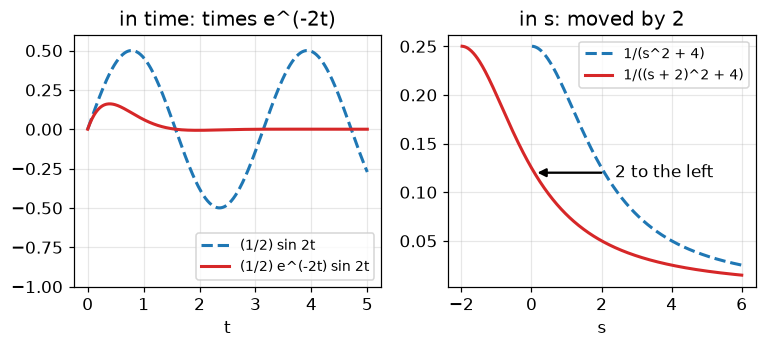

In [10]:
def agrees(function, transform):
    # True when the function of t, transformed forward by the integral, gives the formula in s
    # (it compares at s = 0.5, 1 and 4: use it for functions that do not grow, such as sin, t, e^(-t))
    numeric = sp.lambdify(t, function, "numpy")
    return all(np.isclose(ol.laplace_numeric(numeric, s_value), float(transform.subs(s, s_value)))
               for s_value in S_CHECKS)


F_616 = (s ** 2 + s + 1) / (s ** 3 + s)     # Lebl, Example 6.1.6
fractions_616 = sp.apart(F_616, s)
print("Example 6.1.6:", F_616, "=", fractions_616)
assert sp.simplify(fractions_616 - (1 / s + 1 / (s ** 2 + 1))) == 0                # the book's fractions
assert sp.simplify(sp.together(fractions_616) - F_616) == 0                        # check 1: added back
f_616 = 1 + sp.sin(t)                       # read from the table; the book's answer
assert agrees(f_616, F_616)                                                        # check 2: forward

F_617 = 1 / (s ** 2 + 4 * s + 8)            # Lebl, Example 6.1.7
SHIFT, OMEGA_617 = 2, 2                     # (s + 2)^2 + 2^2
assert sp.expand((s + SHIFT) ** 2 + OMEGA_617 ** 2 - sp.denom(F_617)) == 0         # the completed square
unshifted = sp.sin(OMEGA_617 * t) / OMEGA_617                                      # (1/2) sin 2t
f_617 = sp.exp(-SHIFT * t) * unshifted      # the book's answer
assert agrees(unshifted, F_617.subs(s, s - SHIFT)) and agrees(f_617, F_617)
by_sympy = sp.inverse_laplace_transform(F_617, s, t)                               # SymPy's own inverse
print("Example 6.1.7: sp.inverse_laplace_transform gives", by_sympy)
assert sp.simplify(by_sympy - f_617) == 0

# drawing code: you can skip reading it
T_617 = 5.0                                 # the t axis
HEIGHT_617 = (-1.0, 0.6)                    # room below the curves for the legend
S_END = 6.0                                 # the s axis ends here
LEVEL = 0.12                                # the height at which the arrow of the shift is drawn
LABEL_GAP = 0.3                             # the label starts this far to the right of the arrow
times = np.linspace(0.0, T_617, CURVE_POINTS)
fig, (in_time, in_s) = plt.subplots(1, 2, figsize=WIDE_FIGURE)
in_time.plot(times, sp.lambdify(t, unshifted)(times), "--", color="C0", linewidth=2, label="(1/2) sin 2t")
in_time.plot(times, sp.lambdify(t, f_617)(times), "-", color="C3", linewidth=2, label="(1/2) e^(-2t) sin 2t")
in_time.set_ylim(*HEIGHT_617)
in_time.set_xlabel("t")
in_time.set_title("in time: times e^(-2t)")
in_time.legend(loc="lower right")
transform = sp.lambdify(s, F_617.subs(s, s - SHIFT))                    # 1/(s^2 + 4)
plain = np.linspace(0.0, S_END, CURVE_POINTS)[1:]                       # it holds for s > 0 (0 is left out)
moved = np.linspace(-SHIFT, S_END, CURVE_POINTS)[1:]                    # the shifted one for s > -2
in_s.plot(plain, transform(plain), "--", color="C0", linewidth=2, label="1/(s^2 + 4)")
in_s.plot(moved, transform(moved + SHIFT), "-", color="C3", linewidth=2, label="1/((s + 2)^2 + 4)")
arrow_start = np.sqrt(1 / LEVEL - OMEGA_617 ** 2)                       # where 1/(s^2 + 4) is at that height
in_s.annotate("", xy=(arrow_start - SHIFT, LEVEL), xytext=(arrow_start, LEVEL),
              arrowprops={"arrowstyle": "-|>", "color": "black", "lw": 1.5})
in_s.text(arrow_start + LABEL_GAP, LEVEL, "2 to the left", ha="left", va="center")
in_s.set_xlabel("s")
in_s.set_title("in s: moved by 2")
in_s.legend(loc="upper right")
plt.tight_layout()
plt.show()

*The plot shows* Lebl's Example 6.1.7. Left: $\tfrac12\sin 2t$ (dashed) and the same function times
$e^{-2t}$ (solid), which dies out. Right: their transforms, the same curve moved by 2 to the left (the
arrow); the dashed one is a transform for $s > 0$, the solid one for $s > -2$.

**The procedure** for a quotient of two polynomials in $s$ whose numerator has a lower degree than the
denominator (a *proper rational function*). Every transform of this notebook is of this kind, because a
transform tends to 0 as $s \to \infty$ (Lebl).
1. Factor the denominator into factors $(s + a)$ and quadratics without real roots (notebook 06).
2. Partial fractions: a constant over each factor, $\dfrac{A}{s + a}$ (two fractions,
   $\dfrac{A_1}{s + a} + \dfrac{A_2}{(s + a)^2}$, if the factor appears twice), and a numerator $Bs + C$
   (of degree at most 1) over each quadratic; find the constants by hand or with `sp.apart`. (A
   quadratic that appears twice does not occur in this notebook.)
3. Complete the square in each quadratic, $(s + a)^2 + \omega^2$, and write its numerator as
   $B(s + a) + (C - Ba)$ (Section 6, step 4, does this with numbers).
4. Read each piece in the tables above: $e^{-at}$, $te^{-at}$, $e^{-at}\cos\omega t$,
   $e^{-at}\sin\omega t$.

## 5. Solving an initial value problem

(Session 24.) *In class:* the derivative rule and its table of numbers, the four steps on Lebl's Example
6.2.1 with its figure, the circuit of Section 6, with "Roots and shapes" and the slider. *At home:* the
comparison with undetermined coefficients.

**The derivative rule** (Lebl, Section 6.2.1; the theory exercise of Session 23). By parts with
$u = e^{-st}$ and $v' = g'(t)$, so $u' = -s\,e^{-st}$ and $v = g(t)$:

$$ \mathcal{L}\{g'(t)\} = \int_0^\infty e^{-st}g'(t)\,dt
   = \big[e^{-st}g(t)\big]_0^\infty - \int_0^\infty\big(-s\,e^{-st}\big)g(t)\,dt
   = \big[e^{-st}g(t)\big]_0^\infty + s\int_0^\infty e^{-st}g(t)\,dt = sG(s) - g(0) . $$

The bracket: at infinity $e^{-st}g(t) \to 0$ (when $|g(t)| \le Me^{ct}$ and $s > c$); at $t = 0$ it is
$e^{0}g(0) = g(0)$; so the bracket is $0 - g(0)$. The last integral is $G(s)$ by definition.

The same rule for the function $g'$, whose derivative is $g''$ and whose value at 0 is $g'(0)$ (if $g'$
also satisfies $|g'(t)| \le Me^{ct}$):

$$ \mathcal{L}\{g''\} = s\,\mathcal{L}\{g'\} - g'(0) = s\big(sG(s) - g(0)\big) - g'(0)
   = s^2G(s) - s\,g(0) - g'(0) \qquad\text{(Lebl's Table 6.2.1).} $$

**A derivative becomes a multiplication by $s$, and the initial values appear.** The code tries both
rules on $g(t) = 1 + \sin 2t$, for which $g(0) = 1$ and $g'(0) = 2$.

In [11]:
g = 1 + sp.sin(2 * t)                       # the function on which the two rules are tried
# try another g that does not grow: t ** 2, sp.cos(t), sp.exp(-t)
g_0, dg_0 = float(g.subs(t, 0)), float(g.diff(t).subs(t, 0))            # g(0) and g'(0)
print(f"g(0) = {g_0:g}, g'(0) = {dg_0:g}")
print("     s     L{g'}   s G - g(0)     L{g''}   s^2 G - s g(0) - g'(0)")
for s_value in S_CHECKS:
    G_value = ol.laplace_numeric(sp.lambdify(t, g), s_value)
    of_first = ol.laplace_numeric(sp.lambdify(t, g.diff(t)), s_value)
    of_second = ol.laplace_numeric(sp.lambdify(t, g.diff(t, 2)), s_value)
    rule_first = s_value * G_value - g_0
    rule_second = s_value ** 2 * G_value - s_value * g_0 - dg_0
    print(f"{s_value:6g} {of_first:9.6f} {rule_first:12.6f} {of_second:10.6f} {rule_second:24.6f}")
    assert np.isclose(of_first, rule_first) and np.isclose(of_second, rule_second)

g(0) = 1, g'(0) = 2
     s     L{g'}   s G - g(0)     L{g''}   s^2 G - s g(0) - g'(0)


   0.5  0.235294     0.235294  -1.882353                -1.882353
     1  0.400000     0.400000  -1.600000                -1.600000
     4  0.400000     0.400000  -0.400000                -0.400000


**The four steps** for $ax'' + bx' + cx = f(t)$ with $x(0)$ and $x'(0)$ given. $X(s)$ is the transform
of the unknown $x(t)$: it is the new unknown.

**1** transform both sides; **2** solve for $X(s)$; **3** split $X(s)$ into partial fractions; **4**
invert with the table.

*Lebl, Example 6.2.1:* $x'' + x = \cos 2t$, $x(0) = 0$, $x'(0) = 1$ (no units).
1. By linearity, $\mathcal{L}\{x''\} + \mathcal{L}\{x\} = \mathcal{L}\{\cos 2t\}$. The rule for $x''$ on
   the left, the row $\cos\omega t$ with $\omega = 2$ on the right:
   $\big(s^2X(s) - s\,x(0) - x'(0)\big) + X(s) = \dfrac{s}{s^2 + 4}$. With $x(0) = 0$ and $x'(0) = 1$:
   $s^2X(s) - 1 + X(s) = \dfrac{s}{s^2 + 4}$.
2. $(s^2 + 1)X(s) = \dfrac{s}{s^2 + 4} + 1$, so
   $X(s) = \dfrac{s}{(s^2 + 1)(s^2 + 4)} + \dfrac{1}{s^2 + 1}$.
3. $\dfrac{s}{(s^2 + 1)(s^2 + 4)} = \dfrac{As + B}{s^2 + 1} + \dfrac{Cs + D}{s^2 + 4}$ means
   $s = (As + B)(s^2 + 4) + (Cs + D)(s^2 + 1)$. Multiplied out:
   $s = (A + C)s^3 + (B + D)s^2 + (4A + C)s + (4B + D)$. The powers $s^3$, $s^2$, $s$, $1$ give
   $A + C = 0$, $B + D = 0$, $4A + C = 1$, $4B + D = 0$ (the third minus the first: $3A = 1$; the fourth
   minus the second: $3B = 0$), so $A = \tfrac13$, $C = -\tfrac13$, $B = D = 0$:
   $X(s) = \dfrac13\,\dfrac{s}{s^2 + 1} - \dfrac13\,\dfrac{s}{s^2 + 4} + \dfrac{1}{s^2 + 1}$.
4. The rows $\cos\omega t$ and $\sin\omega t$: $x(t) = \tfrac13\cos t - \tfrac13\cos 2t + \sin t$.

step 2: X(s) = (s**2 + s + 4)/(s**4 + 5*s**2 + 4)  (SymPy adds the two fractions of the text into one: s^4 + 5 s^2 + 4 = (s^2 + 1)(s^2 + 4))


step 3: s/((s^2 + 1)(s^2 + 4)) = -s/(3*(s**2 + 4)) + s/(3*(s**2 + 1))
step 4: x(t) = sin(t) + cos(t)/3 - cos(2*t)/3


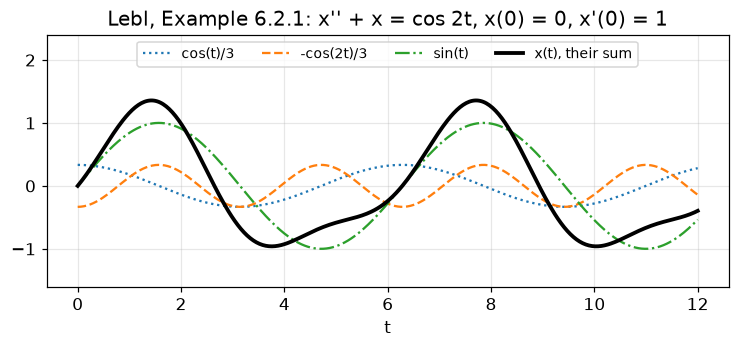

In [12]:
X = sp.symbols("X")                         # the unknown transform X(s), as one letter
EQUATION_621 = (1, 0, 1)                    # Lebl, Example 6.2.1: 1 x'' + 0 x' + 1 x = cos 2t
FORCING_621 = sp.cos(2 * t)
X0_621, V0_621 = 0, 1                       # x(0) and x'(0)
transform_of_forcing = s / (s ** 2 + 4)     # the row cos(omega t) with omega = 2
assert agrees(FORCING_621, transform_of_forcing)

step_1 = sp.Eq(s ** 2 * X - s * X0_621 - V0_621 + X, transform_of_forcing)         # step 1: transform
X_621 = sp.solve(step_1, X)[0]                                                     # step 2: algebra
print("step 2: X(s) =", X_621, " (SymPy adds the two fractions of the text into one:",
      "s^4 + 5 s^2 + 4 = (s^2 + 1)(s^2 + 4))")
assert sp.simplify(X_621 - (s / ((s ** 2 + 1) * (s ** 2 + 4)) + 1 / (s ** 2 + 1))) == 0     # the book's X(s)
fractions_621 = sp.apart(s / ((s ** 2 + 1) * (s ** 2 + 4)), s)                     # step 3
print("step 3: s/((s^2 + 1)(s^2 + 4)) =", fractions_621)
assert sp.simplify(fractions_621 - (s / (3 * (s ** 2 + 1)) - s / (3 * (s ** 2 + 4)))) == 0
TERMS_621 = ((sp.cos(t) / 3, ":", "cos(t)/3"), (-sp.cos(2 * t) / 3, "--", "-cos(2t)/3"),
             (sp.sin(t), "-.", "sin(t)"))                                          # step 4: term, line, label
x_621 = sum(term for term, _, _ in TERMS_621)                                      # the book's x(t)
print("step 4: x(t) =", x_621)
assert sp.simplify(x_621.diff(t, 2) + x_621 - FORCING_621) == 0                    # it satisfies the equation
assert x_621.subs(t, 0) == X0_621 and x_621.diff(t).subs(t, 0) == V0_621           # and the initial values
assert agrees(x_621, X_621)                                                        # and its transform is X(s)

# drawing code: you can skip reading it
T_621 = 12.0
SINGLE_FIGURE = (7.0, 3.3)
HEIGHT_621 = (-1.6, 2.4)                    # room above the curves for the legend
times = np.linspace(0.0, T_621, CURVE_POINTS)
fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
for term, style, label in TERMS_621:
    ax.plot(times, sp.lambdify(t, term)(times), style, linewidth=1.5, label=label)
ax.plot(times, sp.lambdify(t, x_621)(times), "-", color="black", linewidth=2.5, label="x(t), their sum")
ax.set_ylim(*HEIGHT_621)
ax.set_xlabel("t")
ax.set_title("Lebl, Example 6.2.1: x'' + x = cos 2t, x(0) = 0, x'(0) = 1")
ax.legend(loc="upper center", ncol=4)
plt.tight_layout()
plt.show()

*The plot shows* the solution (thick, solid) and its three terms: $\tfrac13\cos t$ (dotted) and $\sin t$
(dash-dot) with period $2\pi$, and $-\tfrac13\cos 2t$ (dashed) with period $\pi$. The solution starts at
0 with slope 1.

**The same problem by undetermined coefficients** (notebook 14; the theory exercise of Session 24). In
notebook 14 the unknown was $y(x)$, with $y_c$ and $y_p$; here the unknown is $x(t)$, so they are $x_c$
and $x_p$.

| | Undetermined coefficients | Laplace transform |
|---|---|---|
| 1 | roots of $r^2 + 1 = 0$: $x_c = C_1\cos t + C_2\sin t$ | transform; the initial values go in |
| 2 | guess $x_p = A\cos 2t + B\sin 2t$; find $A = -\tfrac13$, $B = 0$ | solve for $X(s)$: algebra |
| 3 | $x = C_1\cos t + C_2\sin t - \tfrac13\cos 2t$ | partial fractions |
| 4 | $x(0) = C_1 - \tfrac13 = 0$, $x'(0) = C_2 = 1$ | the table, right to left |
| needs | a guess for $f(t)$ (times $t$ if it repeats $x_c$) | an $f(t)$ with a transform; a table |
| gives | the general solution first, then the constants | the solution of the initial value problem at once |

(Step 2 on the left: with the guess, $x_p'' + x_p = -3A\cos 2t - 3B\sin 2t$, which must be $\cos 2t$.)
Both need constant coefficients, and both give $x(t) = \tfrac13\cos t - \tfrac13\cos 2t + \sin t$.
`ol.forced_response` (variation of parameters, notebook 14) is a third, independent answer. The two
methods meet in the denominator of step 2: $s^2 + 1$ is the characteristic polynomial $r^2 + 1$ with $s$
for $r$, and its roots $\pm i$ give $\cos t$ and $\sin t$; the factor $s^2 + 4$ comes from the input.

In [13]:
# checking code: you can skip reading it; read what it prints
A, B, C1, C2 = sp.symbols("A B C1 C2")
guess = A * sp.cos(2 * t) + B * sp.sin(2 * t)                                      # the shape of cos 2t
left_over = sp.expand(guess.diff(t, 2) + guess - FORCING_621)                      # must be 0 for every t
found = sp.solve([left_over.coeff(sp.cos(2 * t)), left_over.coeff(sp.sin(2 * t))], [A, B])
general = C1 * sp.cos(t) + C2 * sp.sin(t) + guess.subs(found)
constants = sp.solve([general.subs(t, 0) - X0_621, general.diff(t).subs(t, 0) - V0_621], [C1, C2])
print("undetermined coefficients:", found, constants, "-> x(t) =", general.subs(constants))
assert sp.simplify(general.subs(constants) - x_621) == 0                           # the same x(t)
CHECK_POINTS = 41                           # times at which ol.forced_response is compared
check_times = np.linspace(0.0, T_621, CHECK_POINTS)
third = ol.forced_response(check_times, *EQUATION_621, sp.lambdify(t, FORCING_621), X0_621, V0_621)
assert np.allclose(third, sp.lambdify(t, x_621)(check_times))                      # the third answer
print("ol.forced_response: largest difference from x(t)",
      f"{np.max(np.abs(third - sp.lambdify(t, x_621)(check_times))):.0e}")

undetermined coefficients: {A: -1/3, B: 0} {C1: 1/3, C2: 1} -> x(t) = sin(t) + cos(t)/3 - cos(2*t)/3
ol.forced_response: largest difference from x(t) 1e-15


## 6. An RLC circuit

(Session 24, the practical exercise.)

**Conventions (circuit).** The series circuit of notebook 15 (Adkins and Davidson, Section 3.7): a coil
of inductance $L$ (in henry, H), a resistor $R$ (in ohm), a capacitor of capacitance $C$ (in farad, F)
and a source of voltage $E(t)$ (in volt, V; a positive $E$ pushes charge onto the capacitor). $q(t)$ is
the charge on the capacitor, in coulombs; $I = q'$ is the current, in ampere (A), positive when the
charge is increasing; $t$ is in seconds, and $t = 0$ is when the source is connected. Here $L$ is the
inductance, not the transform $\mathcal{L}$, and $C$ the capacitance, not a constant of partial
fractions (step 3 uses $A$, $B$, $D$); $Q(s) = \mathcal{L}\{q(t)\}$. The numbers
are this notebook's own: $L = 1$ H, $R = 2$ ohm, $C = 0.2$ F, a source that fades, $E(t) = 8e^{-t}$ V,
and a capacitor that is already charged, $q(0) = 1$ coulomb, with no current, $q'(0) = 0$ A.

The equation $Lq'' + Rq' + q/C = E(t)$ (notebook 15) is here $q'' + 2q' + 5q = 8e^{-t}$
($q/C = q/0.2 = 5q$).
1. $\big(s^2Q - s\,q(0) - q'(0)\big) + 2\big(sQ - q(0)\big) + 5Q = \dfrac{8}{s + 1}$ (the row $e^{-at}$
   with $a = 1$, times 8), that is $(s^2 + 2s + 5)Q - s - 2 = \dfrac{8}{s + 1}$ (the terms without $Q$
   are $-s\cdot 1 - 0 - 2\cdot 1 = -s - 2$).
2. $Q(s) = \dfrac{\frac{8}{s + 1} + s + 2}{s^2 + 2s + 5} = \dfrac{s^2 + 3s + 10}{(s + 1)(s^2 + 2s + 5)}$
   (multiply the numerator and the denominator by $s + 1$:
   $\frac{8}{s + 1}(s + 1) + (s + 2)(s + 1) = 8 + s^2 + 3s + 2 = s^2 + 3s + 10$).
3. $Q(s) = \dfrac{A}{s + 1} + \dfrac{Bs + D}{s^2 + 2s + 5}$ means
   $s^2 + 3s + 10 = A(s^2 + 2s + 5) + (Bs + D)(s + 1)$. The equality holds for every $s$; choose
   $s = -1$, which makes $s + 1 = 0$: the left side is $1 - 3 + 10 = 8$, the right side
   $A(1 - 2 + 5) + 0 = 4A$, so $A = 2$. Then
   $(Bs + D)(s + 1) = s^2 + 3s + 10 - 2(s^2 + 2s + 5) = -s^2 - s = -s(s + 1)$, so $Bs + D = -s$:
   $B = -1$, $D = 0$, and $Q(s) = \dfrac{2}{s + 1} - \dfrac{s}{s^2 + 2s + 5}$.
4. $s^2 + 2s + 5 = (s + 1)^2 + 4$ and $s = (s + 1) - 1$, so
   $\dfrac{s}{(s + 1)^2 + 4} = \dfrac{s + 1}{(s + 1)^2 + 4} - \dfrac12\cdot\dfrac{2}{(s + 1)^2 + 4}$: the
   transforms of $e^{-t}\cos 2t$ and of $\tfrac12e^{-t}\sin 2t$. So
   $q(t) = 2e^{-t} - \big(e^{-t}\cos 2t - \tfrac12e^{-t}\sin 2t\big)$, by the rows of $e^{-at}$,
   $e^{-at}\cos\omega t$ and $e^{-at}\sin\omega t$ with $a = 1$, $\omega = 2$:

$$ q(t) = e^{-t}\big(2 - \cos 2t + \tfrac12\sin 2t\big) \ \text{coulombs} . $$

The initial values were not imposed at the end: they went in at step 1.

step 2: Q(s) = (s**2 + 3*s + 10)/((s + 1)*(s**2 + 2*s + 5))
step 3: Q(s) = -s/(s**2 + 2*s + 5) + 2/(s + 1)
step 4: q(t) = (sin(2*t)/2 - cos(2*t) + 2)*exp(-t)   and  I(t) = q'(t) = (3*sin(2*t) + 4*cos(2*t) - 4)*exp(-t)/2


largest charge 1.16 coulombs at t = 0.64 s; current between -0.84 A (at t = 1.48 s) and 0.37 A (at t = 0.27 s)


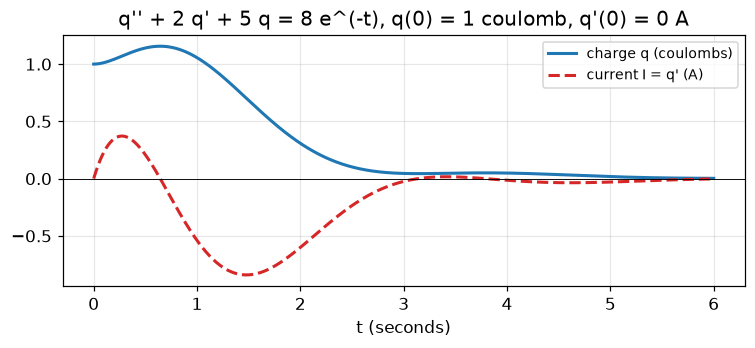

In [14]:
# to try other numbers use the slider below: this cell compares each step with the formulas of the text
INDUCTANCE, RESISTANCE, CAPACITANCE = 1.0, 2.0, 0.2        # H, ohm, F (the notebook's own numbers)
SOURCE_VOLTS, SOURCE_RATE = 8.0, 1.0                       # E(t) = 8 e^(-t) V, t in seconds
CHARGE_0, CURRENT_0 = 1.0, 0.0                             # q(0) in coulombs, q'(0) in ampere
Q = sp.symbols("Q")                                        # the unknown transform Q(s), as one letter
# the same numbers as exact fractions, for SymPy: 1, 2, 1/C = 5, 8, 1, 1, 0
coil, resistor, per_farad, volts, rate, q_0, i_0 = (
    sp.nsimplify(number) for number in (INDUCTANCE, RESISTANCE, 1 / CAPACITANCE, SOURCE_VOLTS, SOURCE_RATE,
                                        CHARGE_0, CURRENT_0))
source = volts * sp.exp(-rate * t)                         # E(t)

step_1 = sp.Eq(coil * (s ** 2 * Q - s * q_0 - i_0) + resistor * (s * Q - q_0) + per_farad * Q,
               volts / (s + rate))                         # the row e^(-at) for the source
Q_s = sp.solve(step_1, Q)[0]                               # step 2
print("step 2: Q(s) =", sp.factor(Q_s))
# (the digits of the text, on purpose: these asserts fail if a number above is changed)
assert sp.simplify(Q_s - (8 / (s + 1) + s + 2) / (s ** 2 + 2 * s + 5)) == 0        # the formula of the text
fractions_q = sp.apart(Q_s, s)                             # step 3
print("step 3: Q(s) =", fractions_q)
assert sp.simplify(fractions_q - (2 / (s + 1) - s / (s ** 2 + 2 * s + 5))) == 0
charge = sp.exp(-t) * (2 - sp.cos(2 * t) + sp.sin(2 * t) / 2)                      # step 4: q(t)
current = sp.simplify(charge.diff(t))                      # I = q'
print("step 4: q(t) =", charge, "  and  I(t) = q'(t) =", current)
assert sp.simplify(coil * charge.diff(t, 2) + resistor * current + per_farad * charge - source) == 0
assert charge.subs(t, 0) == q_0 and current.subs(t, 0) == i_0                      # the initial values
assert agrees(charge, Q_s)                                                         # its transform is Q(s)
T_CIRCUIT = 6.0                             # seconds
FINE_POINTS = 6001                          # a point every 0.001 s: the times printed below are read from it
times = np.linspace(0.0, T_CIRCUIT, FINE_POINTS)
charges, currents = sp.lambdify(t, charge)(times), sp.lambdify(t, current)(times)
check_times = np.linspace(0.0, T_CIRCUIT, CHECK_POINTS)
third = ol.forced_response(check_times, INDUCTANCE, RESISTANCE, 1 / CAPACITANCE, sp.lambdify(t, source),
                           CHARGE_0, CURRENT_0)
assert np.allclose(third, sp.lambdify(t, charge)(check_times))                     # variation of parameters
print(f"largest charge {charges.max():.2f} coulombs at t = {times[charges.argmax()]:.2f} s; "
      f"current between {currents.min():.2f} A (at t = {times[currents.argmin()]:.2f} s) and "
      f"{currents.max():.2f} A (at t = {times[currents.argmax()]:.2f} s)")

# drawing code: you can skip reading it
fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
ax.plot(times, charges, "-", color="C0", linewidth=2, label="charge q (coulombs)")
ax.plot(times, currents, "--", color="C3", linewidth=2, label="current I = q' (A)")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_xlabel("t (seconds)")
ax.set_title("q'' + 2 q' + 5 q = 8 e^(-t), q(0) = 1 coulomb, q'(0) = 0 A")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

*The plot shows* the charge (solid): it first rises a little, to 1.16 coulombs at $t = 0.64$ s (the
source pushes more charge in), then falls towards 0; a second, faint rise can just be seen near
$t = 3.5$ s. The current (dashed) starts at 0, rises to 0.37 A at $t = 0.27$ s, falls to $-0.84$ A at
$t = 1.48$ s, and dies out.

**Roots and shapes.** The denominator of $Q(s)$ is $(s + 1)(s^2 + 2s + 5)$. Its roots are $-1$, from
the source, and $-1 \pm 2i$, the roots of $s^2 + 2s + 5$: these are the characteristic roots of the
circuit (notebook 06, with $s$ for $r$). Each root gives a term of $q(t)$: $-1$ gives $e^{-t}$;
$-1 \pm 2i$ give $e^{-t}\cos 2t$ and $e^{-t}\sin 2t$. The real part, with its sign changed, is the rate
of decay (1 per second); the imaginary part is the angular frequency (2 rad per second). All three roots
have a negative real part, so $q(t) \to 0$. (With another resistance the root of the source can also be
a root of the circuit: Exercise 3(vi).)

In [15]:
denominator_roots = sp.roots(sp.denom(sp.together(Q_s)), s)            # each root with how often it occurs
print("roots of the denominator of Q(s):", denominator_roots)
print("(SymPy writes the imaginary unit i as I; the 1 after each colon: the root occurs once)")
circuit_roots = ol.characteristic_roots(INDUCTANCE, RESISTANCE, 1 / CAPACITANCE)    # of L r^2 + R r + 1/C
source_root = -SOURCE_RATE                                              # of s + 1, from E(t) = 8 e^(-t)


def in_order(roots):
    # the roots as complex numbers, sorted by real part and then by imaginary part
    return sorted((complex(root) for root in roots), key=lambda root: (root.real, root.imag))


assert np.allclose(in_order(denominator_roots), in_order([*circuit_roots, source_root]))
assert np.allclose(in_order(circuit_roots), [-1 - 2j, -1 + 2j])                    # the roots of the text

roots of the denominator of Q(s): {-1: 1, -1 - 2*I: 1, -1 + 2*I: 1}
(SymPy writes the imaginary unit i as I; the 1 after each colon: the root occurs once)


**Slider: the resistance.** The roots of the circuit do not depend on the source: they are the roots of
$Ls^2 + Rs + 1/C$. To see what they decide, the source is now switched off: the capacitor, charged with
1 coulomb, discharges through the coil and the resistor, $q'' + Rq' + 5q = 0$, $q(0) = 1$ coulomb,
$q'(0) = 0$ A, with $R$ from 0.5 to 8 ohm. The left panel draws each root as a circle in a plane: its
real part across, its imaginary part up, so two real roots lie on the horizontal axis. Before moving it:
for which $R$ do the two circles meet on the horizontal axis? The roots of $Ls^2 + Rs + 1/C$ are equal
when the discriminant $R^2 - 4L/C$ is 0: compute $R$ from $R^2 = 4L/C$, then check with the slider and
with the lowest value of $q$, which is written above the graph.

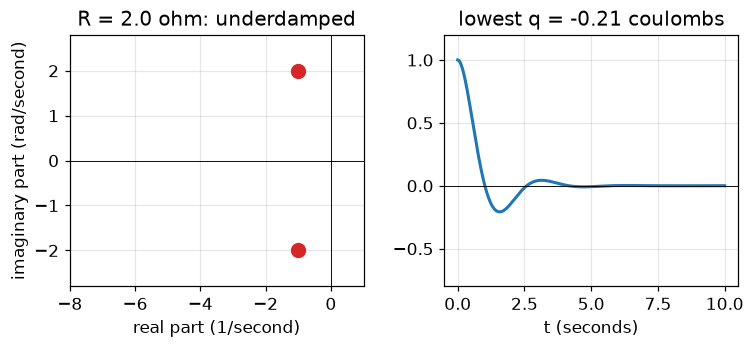

In [16]:
DEFAULT_R = RESISTANCE
R_RANGE = (0.5, 8.0, 0.1)                   # ohm: minimum, maximum, step
T_SLIDER_2 = 10.0                           # seconds
CHARGE_WINDOW = (-0.8, 1.2)                 # coulombs
CRITICAL_R = 2 * np.sqrt(INDUCTANCE / CAPACITANCE)         # ohm: R^2 = 4 L / C
ROOT_WINDOW = ((-8.0, 1.0), (-2.8, 2.8))    # real part, imaginary part
ROOT_SIZE = 9                               # markers: a root
OSCILLATING = ("underdamped", "undamped")   # the words of ol.damping_regime for complex roots


def discharge(times, R):
    # q(t) in coulombs at these times (seconds) for the resistance R (ohm): no source, q(0) = 1, q'(0) = 0
    return ol.free_response(times, INDUCTANCE, R, 1 / CAPACITANCE, CHARGE_0, CURRENT_0)


def lowest_charge(R):
    # the lowest value of q(t), t >= 0, in the discharge. With complex roots -p +- i omega_1 (notebook 07):
    # q' = 0 where sin(omega_1 t) = 0, and the first such time after the start, pi / omega_1, is the lowest
    # point. With real roots q stays positive and falls to 0: the lowest value is 0, never reached.
    if ol.damping_regime(INDUCTANCE, R, 1 / CAPACITANCE) not in OSCILLATING:
        return 0.0
    omega_1 = abs(ol.characteristic_roots(INDUCTANCE, R, 1 / CAPACITANCE)[0].imag)
    return float(discharge(np.pi / omega_1, R))


def draw_roots(ax, roots, title):
    # the two roots of the circuit in the plane (real part across, imaginary part up)
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.axvline(0.0, color="black", linewidth=0.6)
    ax.plot([root.real for root in roots], [root.imag for root in roots], "o", color="C3",
            markersize=ROOT_SIZE)
    ax.set_xlim(*ROOT_WINDOW[0])
    ax.set_ylim(*ROOT_WINDOW[1])
    ax.set_xlabel("real part (1/second)")
    ax.set_ylabel("imaginary part (rad/second)")
    ax.set_title(title)


def plot_circuit(R=DEFAULT_R):
    # left: the roots of L s^2 + R s + 1/C; right: the discharge q(t) and its lowest value
    roots = ol.characteristic_roots(INDUCTANCE, R, 1 / CAPACITANCE)
    grid = np.linspace(0.0, T_SLIDER_2, CURVE_POINTS)
    fig, (plane, graph) = plt.subplots(1, 2, figsize=WIDE_FIGURE)
    draw_roots(plane, roots, f"R = {R:.1f} ohm: {ol.damping_regime(INDUCTANCE, R, 1 / CAPACITANCE)}")
    graph.plot(grid, discharge(grid, R), "-", color="C0", linewidth=2)
    graph.axhline(0.0, color="black", linewidth=0.6)
    graph.set_ylim(*CHARGE_WINDOW)
    graph.set_xlabel("t (seconds)")
    graph.set_title(f"lowest q = {lowest_charge(R):.2g} coulombs")
    plt.tight_layout()
    plt.show()


plot_circuit()

In [17]:
interact(plot_circuit, R=FloatSlider(value=DEFAULT_R, min=R_RANGE[0], max=R_RANGE[1], step=R_RANGE[2],
                                     description="R (ohm)", continuous_update=False));

interactive(children=(FloatSlider(value=2.0, continuous_update=False, description='R (ohm)', max=8.0, min=0.5)...

*The static plot shows*, for $R = 2$ ohm, the roots $-1 \pm 2i$ of the circuit (left; the same as with
the source) and the discharge (right): the charge falls from 1 coulomb, crosses 0 at $t = 1.02$ s, is
lowest, $-0.21$ coulomb, at $t = 1.57$ s, and comes back to 0.

(Answer: $R^2 = 4L/C = 20$, so $R = \sqrt{20} \approx 4.47$ ohm, the **critical resistance**,
$R = 2\sqrt{L/C}$. It is the critical damping $c_{crit} = 2\sqrt{mk}$ of notebook 07 with the letters of
the circuit ($L$ for $m$, $R$ for $c$, $1/C$ for $k$, notebook 15). On the slider, up to 4.4 ohm the two
circles are one above the other (complex roots, underdamped): $q(t)$ is $e^{-Rt/2}$ times a cosine and a
sine, it crosses 0, and its lowest value is negative. From 4.5 ohm the circles lie on the horizontal axis
(real roots, overdamped): $q(t)$ is a sum of two exponentials, it stays positive and falls towards 0
without reaching it (the title then shows 0). The eye sees less than the numbers: the lowest value is
$-0.70$ at 0.5 ohm, $-0.21$ at 2 ohm, $-0.058$ at 3 ohm, $-0.0019$ at 4 ohm and
$-0.00000003$ at 4.4 ohm, so on the graph the oscillation seems to stop near 3.5 ohm, well before the
roots say so.)

In [18]:
# checking code: you can skip reading it; read what it prints
T_LONG = 40.0                               # seconds: long enough for a crossing near the critical resistance
GRID_AGREEMENT = 1e-4                       # the lowest point of a grid against the true lowest value
LONG_POINTS = 40001
SHOWN_R = (0.5, 2.0, 3.0, 4.0, 4.4, 4.5, 8.0)              # ohm: the values printed below
long_grid = np.linspace(0.0, T_LONG, LONG_POINTS)
assert np.isclose(CRITICAL_R ** 2, 4 * INDUCTANCE / CAPACITANCE) and np.isclose(CRITICAL_R, np.sqrt(20))
for R in np.arange(R_RANGE[0], R_RANGE[1] + R_RANGE[2] / 2, R_RANGE[2]):       # every position of the slider
    charges_R = discharge(long_grid, R)
    if R < CRITICAL_R:                      # complex roots: the charge crosses 0
        assert lowest_charge(R) < 0 and charges_R.min() < 0
        assert lowest_charge(R) <= charges_R.min() <= lowest_charge(R) * (1 - GRID_AGREEMENT)
    else:                                   # real roots: the charge never reaches 0
        assert lowest_charge(R) == 0 and np.all(charges_R > 0)
print(f"critical resistance: {CRITICAL_R:.4f} ohm")
for R in SHOWN_R:
    print(f"R = {R:g} ohm: {ol.damping_regime(INDUCTANCE, R, 1 / CAPACITANCE)}, "
          f"lowest q = {lowest_charge(R):.2g} coulombs")
first_zero = long_grid[np.argmax(discharge(long_grid, DEFAULT_R) < 0)]
print(f"R = {DEFAULT_R:g} ohm: q first below 0 at t = {first_zero:.2f} s; lowest at t = "
      f"{np.pi / abs(circuit_roots[0].imag):.2f} s")

critical resistance: 4.4721 ohm
R = 0.5 ohm: underdamped, lowest q = -0.7 coulombs
R = 2 ohm: underdamped, lowest q = -0.21 coulombs
R = 3 ohm: underdamped, lowest q = -0.058 coulombs
R = 4 ohm: underdamped, lowest q = -0.0019 coulombs
R = 4.4 ohm: underdamped, lowest q = -3.1e-08 coulombs
R = 4.5 ohm: overdamped, lowest q = 0 coulombs
R = 8 ohm: overdamped, lowest q = 0 coulombs
R = 2 ohm: q first below 0 at t = 1.02 s; lowest at t = 1.57 s


## 7. What the method cannot do, and where to go next

* The equation must be **linear with constant coefficients**. A term such as $t\,x'$ or $x^2$ is a
  product, and the transform of a product is not the product of the transforms: no equation of algebra
  comes out (Lebl, Section 6.2).
* The input must **have a transform**: $e^{t^2}$ has none.
* Step 3 needs the roots of the denominator of $X(s)$, as the characteristic equation does.
* For the inputs of this notebook undetermined coefficients work as well (Section 5). The transform
  shows its strength with inputs that switch on and off, or that strike like a hammer: notebook 20
  (steps, impulses, convolution).

## 8. Exercises

Final answers are at the end; try first. After Session 23: Exercises 1(a)-(c), 2(a)-(c), 3(i)-(ii);
after Session 24: the rest. A formula is typed with SymPy and the letters `s` or `t` of this notebook,
for example `my_F = 1 / (s + 2)` or `my_f = sp.exp(-2 * t) * sp.sin(t)`.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

* (a) *(From Lebl, Table 6.1.1)* $\mathcal{L}\{e^{3t}\}$, as a formula in $s$, and the smallest number
  $c$ such that the transform exists for every $s > c$.
* (b) *(From Lebl's warning)* True or False:
  $\mathcal{L}\{te^{-t}\} = \mathcal{L}\{t\}\,\mathcal{L}\{e^{-t}\}$.
* (c) *(From Lebl, Exercise 6.1.7)* Which form of partial fractions is right for
  $\dfrac{1}{(s - 1)^2(s + 1)}$? Answer 1, 2 or 3:
  **1.** $\dfrac{A}{s - 1} + \dfrac{B}{s + 1}$;
  **2.** $\dfrac{A}{s - 1} + \dfrac{B}{(s - 1)^2} + \dfrac{C}{s + 1}$;
  **3.** $\dfrac{A}{(s - 1)^2} + \dfrac{B}{s + 1}$.
* (d) (After Session 24.) If $x(0) = 2$ and $x'(0) = -1$, then $\mathcal{L}\{x''(t)\} = s^2X(s) + \dots$:
  type the rest, a formula in $s$.

In [19]:
my_transform_1a = None          # a formula in s
my_edge_1a = None               # a number: the smallest c
my_product_rule = None          # True or False
my_form = None                  # 1, 2 or 3
my_rest = None                  # a formula in s
# ---- your answers go above this line; the lines below check them (nothing to change) ----

t, s = sp.symbols("t s", positive=True)     # SymPy's t and s again (a cell above may have changed them)
RATE_1A = 3                                 # e^(3t)
CHECK_S = (1.0, 5.0)                        # formulas in s are compared for s between these numbers
row_1a = {row.name: row for row in ol.laplace_table(a=-RATE_1A)}["e^(-at)"]       # e^(3t): a = -3
ol.check_formula("Exercise 1a, transform", my_transform_1a, 1 / (s - RATE_1A), s,
                 (row_1a.s_min + CHECK_S[0], row_1a.s_min + CHECK_S[1]))
ol.check("Exercise 1a, smallest c", my_edge_1a, row_1a.s_min)
same_at_every_s = all(
    np.isclose(ol.laplace_numeric(lambda t: t * np.exp(-t), s_value),
               ol.laplace_numeric(lambda t: t, s_value) * ol.laplace_numeric(lambda t: np.exp(-t), s_value))
    for s_value in CHECK_S)
ol.check("Exercise 1b", my_product_rule, same_at_every_s)
A, B, C = sp.symbols("A B C")
FRACTION_1C = 1 / ((s - 1) ** 2 * (s + 1))                                 # Lebl, Exercise 6.1.7
FORMS = {1: A / (s - 1) + B / (s + 1), 2: A / (s - 1) + B / (s - 1) ** 2 + C / (s + 1),
         3: A / (s - 1) ** 2 + B / (s + 1)}
# a form is right when constants can be found: the numerator of (form - fraction) must be 0 for every s
(right_form,) = [number for number, form in FORMS.items()
                 if sp.solve(sp.Poly(sp.numer(sp.together(form - FRACTION_1C)), s).all_coeffs(), [A, B, C])]
ol.check("Exercise 1c", my_form, right_form)
X0_1D, V0_1D = 2, -1                        # x(0) and x'(0)
ol.check_formula("Exercise 1d", my_rest, -s * X0_1D - V0_1D, s, CHECK_S);

Exercise 1a, transform: no answer yet (replace None with your formula)
Exercise 1a, smallest c: no answer yet (replace None with your value)
Exercise 1b: no answer yet (replace None with your value)
Exercise 1c: no answer yet (replace None with your value)
Exercise 1d: no answer yet (replace None with your formula)


### Exercise 2 - By hand, then check

**(a)** *From Lebl, Exercise 6.1.1 in the text of Section 6.1* (verify the table: here one row).
$\mathcal{L}\{t^2\}$ from the definition, by parts. First step: $u = t^2$, $v' = e^{-st}$; the bracket is
0, and the integral that is left is $\dfrac2s\displaystyle\int_0^\infty te^{-st}\,dt$, which Section 2
computed.

**(b)** *Lebl, Exercise 6.1.13.* The inverse transform of $\dfrac{8}{s^3(s + 2)}$, a formula in $t$.
First step: $\dfrac{A}{s} + \dfrac{B}{s^2} + \dfrac{C}{s^3} + \dfrac{D}{s + 2}$ (a factor that appears
three times needs three fractions).

**(c)** *Lebl, Exercise 6.1.15.* $\mathcal{L}\{e^{-t}\sin t\}$, a formula in $s$, with the shifting
property.

**(d)** (After Session 24.) *From Lebl, Exercise 6.2.4, with numbers.* Convention: $x(t)$ is the
displacement of the mass from its rest position, in cm, positive when the spring is stretched; $t$ in
seconds. A mass $m = 1$ kg on a spring $k = 10$ N/m with a damper $c = 2$ kg/s (the $m$, $c$, $k$ of
notebook 07): $x'' + 2x' + 10x = 0$, $x(0) = 2$ cm, $x'(0) = 1$ cm/s. Find $x(t)$, a formula in $t$, by
the four steps. First step: $s^2X - 2s - 1 + 2(sX - 2) + 10X = 0$.

In [20]:
my_transform_2a = None          # a formula in s
my_inverse_2b = None            # a formula in t
my_transform_2c = None          # a formula in s
my_spring_2d = None             # a formula in t
# ---- your answers go above this line; the lines below check them (nothing to change) ----

t, s = sp.symbols("t s", positive=True)     # SymPy's t and s again (a cell above may have changed them)
CHECK_S_2 = (1.0, 5.0)                      # formulas in s are compared for s between these numbers
CHECK_T_2 = (0.0, 3.0)                      # formulas in t for t between these numbers
SAMPLE_S = 2.0                              # where the expected formulas are checked against the integral
row_2a = {row.name: row for row in ol.laplace_table()}["t^2"]
expected_2a = sp.factorial(2) / s ** 3
assert np.isclose(float(expected_2a.subs(s, SAMPLE_S)), row_2a.transform(SAMPLE_S))
ol.check_formula("Exercise 2a", my_transform_2a, expected_2a, s, CHECK_S_2)

EXERCISE_6113 = 8 / (s ** 3 * (s + 2))                                     # Lebl, Exercise 6.1.13
expected_2b = 2 * t ** 2 - 2 * t + 1 - sp.exp(-2 * t)                      # the answer printed in the book
assert np.isclose(ol.laplace_numeric(sp.lambdify(t, expected_2b), SAMPLE_S),
                  float(EXERCISE_6113.subs(s, SAMPLE_S)))
ol.check_formula("Exercise 2b", my_inverse_2b, expected_2b, t, CHECK_T_2)

expected_2c = 1 / ((s + 1) ** 2 + 1)                                       # the shifted row sin(omega t)
assert sp.simplify(expected_2c - 1 / (s ** 2 + 2 * s + 2)) == 0            # the answer printed in the book
assert np.isclose(ol.laplace_numeric(lambda t: np.exp(-t) * np.sin(t), SAMPLE_S),
                  float(expected_2c.subs(s, SAMPLE_S)))
ol.check_formula("Exercise 2c", my_transform_2c, expected_2c, s, CHECK_S_2)

MASS_2D, DAMPER_2D, SPRING_2D = 1.0, 2.0, 10.0                             # kg, kg/s, N/m
X0_2D, V0_2D = 2.0, 1.0                                                    # cm, cm/s
half_rate = DAMPER_2D / (2 * MASS_2D)                                      # p of notebook 07
frequency = np.sqrt(SPRING_2D / MASS_2D - half_rate ** 2)                  # omega_1 of notebook 07
expected_2d = sp.exp(-half_rate * t) * (X0_2D * sp.cos(frequency * t)
                                        + (V0_2D + half_rate * X0_2D) / frequency * sp.sin(frequency * t))
sample_times = np.linspace(*CHECK_T_2, ol.FORMULA_SAMPLES)                 # where check_formula compares
assert np.allclose(sp.lambdify(t, expected_2d)(sample_times),
                   ol.free_response(sample_times, MASS_2D, DAMPER_2D, SPRING_2D, X0_2D, V0_2D))
ol.check_formula("Exercise 2d", my_spring_2d, expected_2d, t, CHECK_T_2);

Exercise 2a: no answer yet (replace None with your formula)
Exercise 2b: no answer yet (replace None with your formula)
Exercise 2c: no answer yet (replace None with your formula)
Exercise 2d: no answer yet (replace None with your formula)


### Exercise 3 - Explore

* (i) *(Lebl, Exercise 6.1.4)* Find $\mathcal{L}\{\cos^2\omega t\}$. First step: the double angle,
  $\cos^2\omega t = \tfrac12(1 + \cos 2\omega t)$, then two rows of the table. Check your formula with
  `ol.laplace_numeric` for $\omega = 3$ at two values of $s$ (the template in the cell below).
* (ii) *(Lebl's Table 6.1.1)* Find the rows of $\sinh\omega t$ and $\cosh\omega t$ from the row of
  $e^{-at}$ (with $a = -\omega$ and $a = \omega$) and linearity. Why do they need $s > \omega$?
* (iii) (After Session 24.) *(Lebl, Exercise 6.2.7)* $\mathcal{L}\{-t f(t)\} = F'(s)$, the derivative of
  $F$ with respect to $s$. Check it on $f(t) = \sin t$: numerically, with
  `ol.laplace_numeric(lambda t: -t * np.sin(t), 2.0)`, and with SymPy:
  `sp.simplify(sp.laplace_transform(-t * sp.sin(t), t, s, noconds=True) - sp.diff(1 / (s ** 2 + 1), s))`
  must print 0 (SymPy writes the transform with the imaginary unit `I`; the difference shows that the
  two are equal).
* (iv) (After Session 24.) *(Lebl, Example 6.2.4)* The transform of $\int_0^t f(\tau)\,d\tau$ is
  $F(s)/s$. Use it to invert $\dfrac{1}{s(s^2 + 1)}$ (the integral of $\sin\tau$ from 0 to $t$), then
  check with `sp.apart` and with the table.
* (v) (After Session 24.) Convention: as in Section 6 ($q$ in coulombs, $I = q'$ in ampere, $t$ in
  seconds, the same $L$, $R$, $C$ and start). A battery of 8 V replaces the fading source:
  $q'' + 2q' + 5q = 8$, $q(0) = 1$ coulomb, $q'(0) = 0$ A. Find $q(t)$ by the four steps (the row 1 gives
  $8/s$), and the charge it tends to. What is that number in terms of $C$ and the 8 V?
* (vi) (After Session 24.) Convention: as in Section 6, with its fading source and its start, but
  $R = 6$ ohm: $q'' + 6q' + 5q = 8e^{-t}$, $q(0) = 1$ coulomb, $q'(0) = 0$ A. Now
  $s^2 + 6s + 5 = (s + 1)(s + 5)$: the root $-1$ of the source is also a root of the circuit. Find
  $Q(s)$ and $q(t)$ (`sp.apart` helps), and check: with your formula typed as `my_q` (with `np.exp`
  and `times` for $t$),
  `np.max(np.abs(ol.forced_response(times, 1, 6, 5, lambda t: 8 * np.exp(-t), 1, 0) - my_q))` must be
  about 1e-15. Which term is new?
* (vii) In the cell of Section 3 that prints "no value", set `S_INSIDE = 40.0`: a number comes out for
  $e^{t^2}$. Why is it wrong? (`ol.laplace_numeric` looks up to $t = 700/s$, where $e^{-st}$ becomes too
  small for the computer to hold.)

In [21]:
# your code here. (i) a template: select the five lines below and press Ctrl + / (it removes the #
# and the space after it), then replace the three dots by your formula
# OMEGA = 3.0
# for s_value in (1.0, 2.0):
#     by_integral = ol.laplace_numeric(lambda t: np.cos(OMEGA * t) ** 2, s_value)
#     my_value = ...                  # your formula, with s_value for s and OMEGA for omega
#     print(s_value, by_integral, my_value)

### Exercise 4 - Explain

(After Session 24; two or three sentences.) In Session 13 (notebook 14), when the input repeats a
solution of the homogeneous equation, the guess must be multiplied by the variable. The Laplace method
has no such rule. Why does it not need one? First step: solve $x' + x = e^{-t}$, $x(0) = 0$ by the four
steps, and look at the denominator of $X(s)$.

## 9. Answers

Final answers only; full solutions are given after the sessions.

<details>
<summary>Click to open (after trying)</summary>

1. (a) `1 / (s - 3)`, and $c = 3$ (the row $e^{-at}$ with $a = -3$). (b) False: the left side is
   $1/(s + 1)^2$ (shifting), the right side $1/(s^2(s + 1))$. (c) 2: a factor that appears twice needs
   both $\dfrac{A}{s - 1}$ and $\dfrac{B}{(s - 1)^2}$ ($A = -\tfrac14$, $B = \tfrac12$, $C = \tfrac14$).
   (d) `-2 * s + 1`: $\mathcal{L}\{x''\} = s^2X(s) - 2s + 1$.
2. (a) `2 / s**3`. (b) `2 * t**2 - 2 * t + 1 - sp.exp(-2 * t)` (the book's answer; the fractions are
   $\dfrac1s - \dfrac{2}{s^2} + \dfrac{4}{s^3} - \dfrac{1}{s + 2}$). (c) `1 / ((s + 1)**2 + 1)`, which is
   the book's $\dfrac{1}{s^2 + 2s + 2}$. (d) `sp.exp(-t) * (2 * sp.cos(3 * t) + sp.sin(3 * t))`, in cm:
   $X(s) = \dfrac{2s + 5}{s^2 + 2s + 10} = \dfrac{2(s + 1) + 3}{(s + 1)^2 + 9}$.
3. (i) $\dfrac{1}{2s} + \dfrac{s}{2(s^2 + 4\omega^2)}$; for $\omega = 3$ at $s = 2$: 0.275.
   (ii) $\sinh\omega t = \tfrac12(e^{\omega t} - e^{-\omega t})$ gives
   $\tfrac12\Big(\dfrac{1}{s - \omega} - \dfrac{1}{s + \omega}\Big) = \dfrac{\omega}{s^2 - \omega^2}$, and
   $\cosh\omega t$ gives $\dfrac{s}{s^2 - \omega^2}$; the part $e^{\omega t}$ has a transform only for
   $s > \omega$. (iii) Both are $-\dfrac{2s}{(s^2 + 1)^2}$; at $s = 2$: $-0.16$.
   (iv) $1 - \cos t$; `sp.apart` gives $\dfrac1s - \dfrac{s}{s^2 + 1}$.
   (v) $Q(s) = \dfrac{8}{5s} - \dfrac35\,\dfrac{s + 2}{s^2 + 2s + 5}$, so
   $q(t) = \tfrac85 - \tfrac35e^{-t}\big(\cos 2t + \tfrac12\sin 2t\big)$ coulombs, which tends to
   $8/5 = 1.6$ coulombs: the capacitance times the voltage of the battery, $0.2 \cdot 8$.
   (vi) $Q(s) = \dfrac{s^2 + 7s + 14}{(s + 1)^2(s + 5)}
   = \dfrac{3/4}{s + 1} + \dfrac{2}{(s + 1)^2} + \dfrac{1/4}{s + 5}$, so
   $q(t) = \big(\tfrac34 + 2t\big)e^{-t} + \tfrac14e^{-5t}$ coulombs: the term $te^{-t}$ is new, because
   $(s + 1)$ appears twice under $Q(s)$ (Exercise 4).
   (vii) About 0.025 comes out, the area up to $t = 700/40 = 17.5$, where $e^{t(t - 40)}$ is still
   tiny; the product grows without bound only after $t = 40$, where the computer no longer looks. For
   $s$ up to about 36 the function sees the growth coming and gives no value.
4. The repeated factor appears by itself. $(s + 1)X(s) = \dfrac{1}{s + 1}$ gives
   $X(s) = \dfrac{1}{(s + 1)^2}$: the root $-1$ of the equation and the root $-1$ of the input multiply
   in the denominator, and the table (with the shift) reads $1/(s + 1)^2$ as $te^{-t}$. The factor $t$
   comes out of the algebra, with no rule to remember.

</details>

*For those who read the book:* two misprints in Lebl's text. In Section 6.1.1 the standard equation is
printed $mx'' = cx' + kx = f(t)$ for $mx'' + cx' + kx = f(t)$, and in Example 6.2.1
$s^2X(x) - sx(0) + x'(0)$ is printed for $s^2X(s) - sx(0) - x'(0)$; the next lines of the book are
right.

**Where to go next:** notebook 20, steps, impulses and convolution.